## Test Grid SANOS



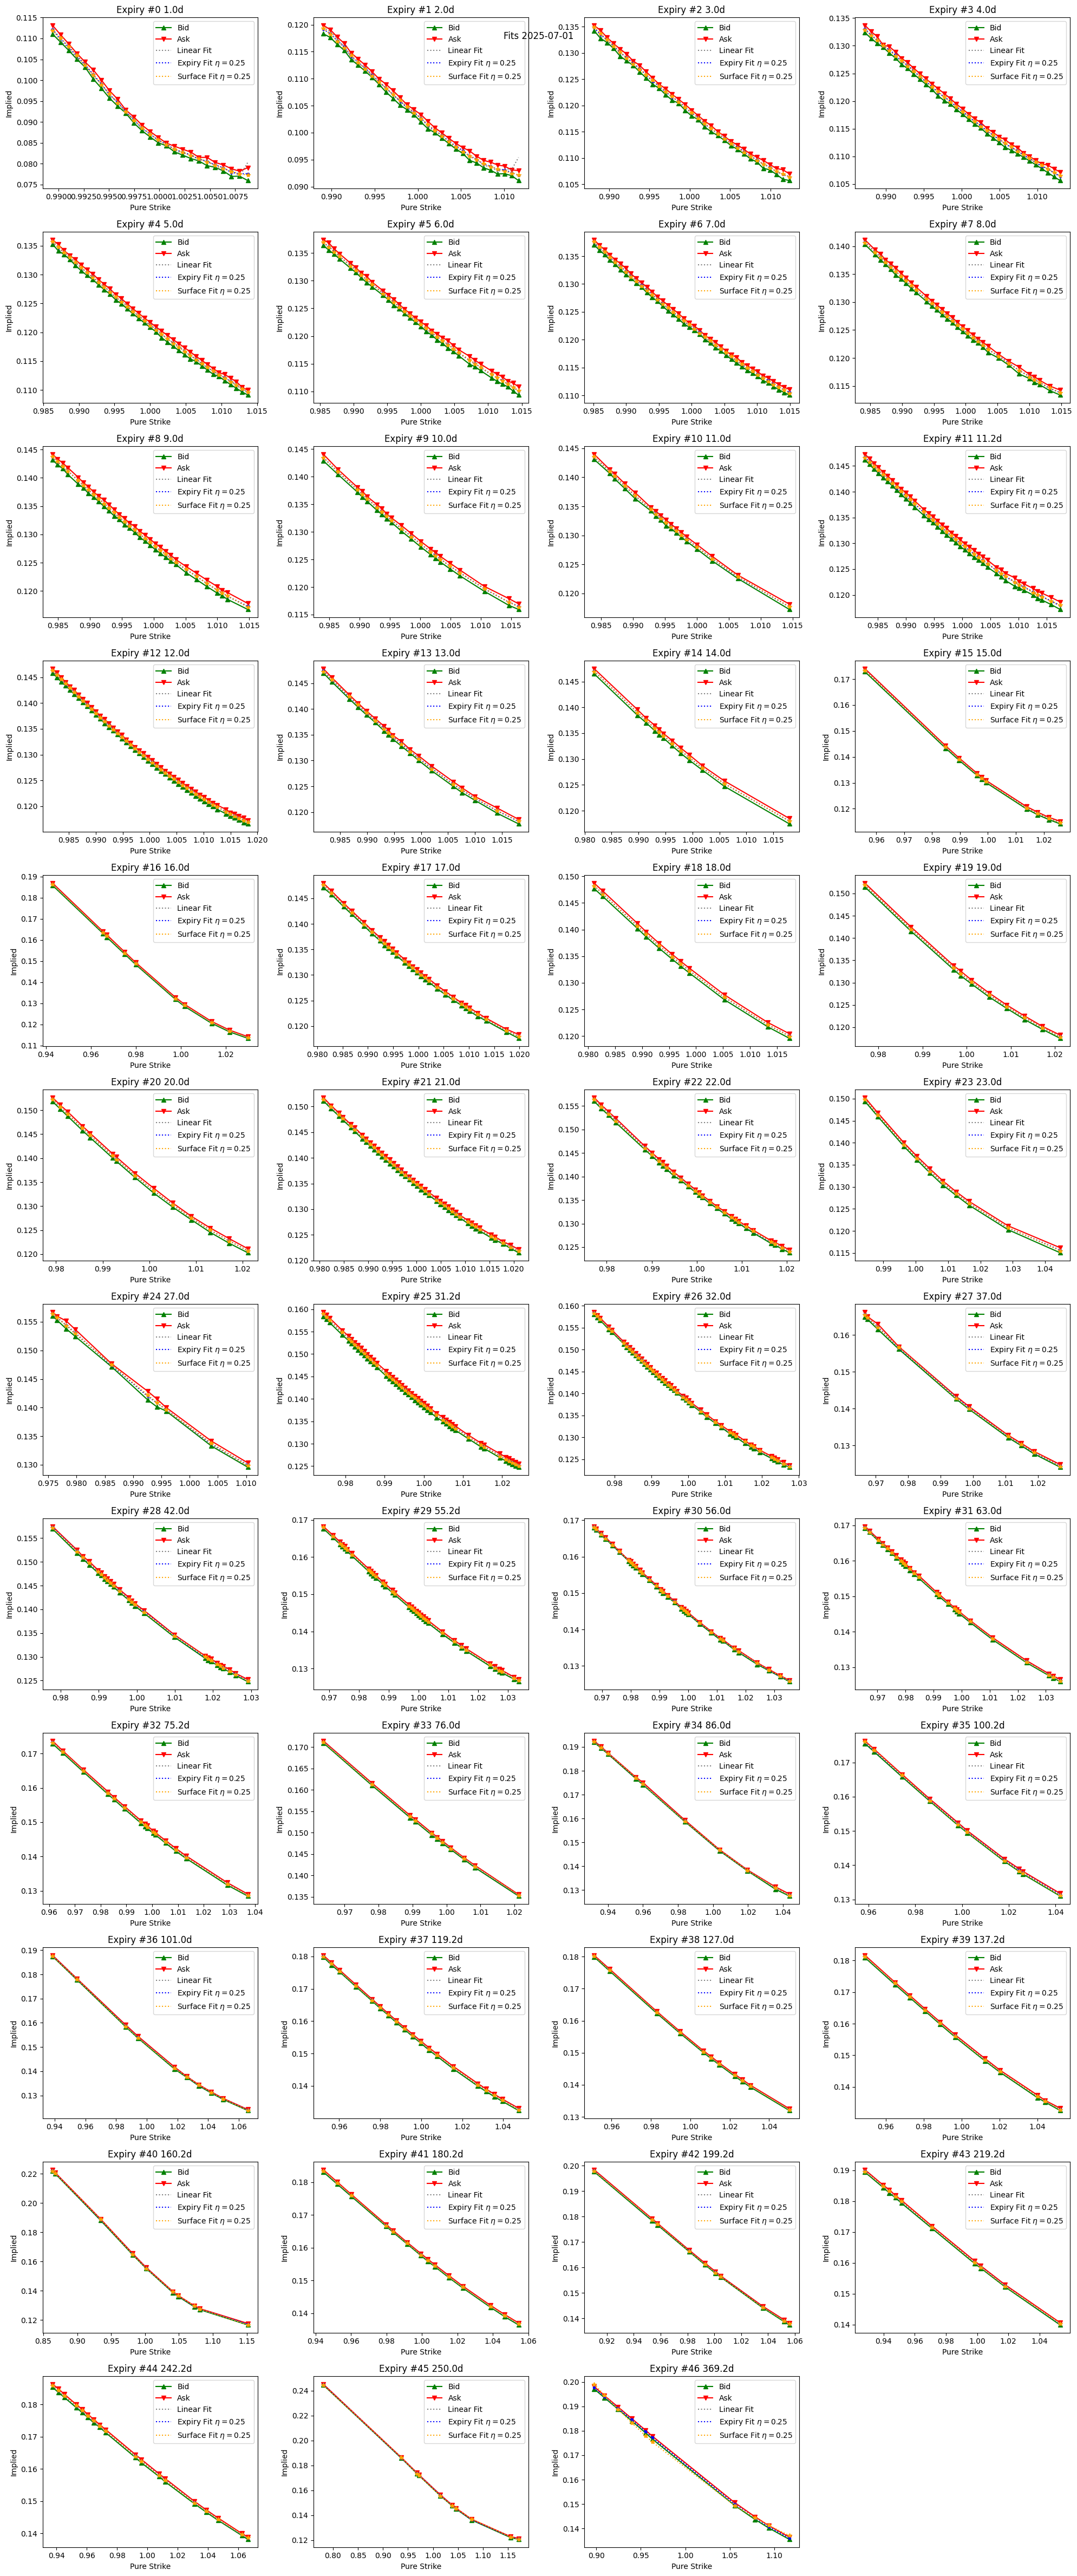

00: Surface 2025-07-01 expiry #0 1.0d: Generating extended strikes... using 27 extended strikes based on 25 market strikes.
00: Surface 2025-07-01 expiry #0 1.0d: Soft linear per-expiry no-arbitrage fit succeeded within bid/ask. This took 0.01s.
00: Surface 2025-07-01 expiry #1 2.0d: Generating extended strikes... using 31 extended strikes based on 29 market strikes.
00: Surface 2025-07-01 expiry #1 2.0d: Soft linear per-expiry no-arbitrage fit succeeded within bid/ask. This took 6.65ms.
00: Surface 2025-07-01 expiry #2 3.0d: Generating extended strikes... using 33 extended strikes based on 31 market strikes.
00: Surface 2025-07-01 expiry #0 1.0d: Generating extended strikes... using 27 extended strikes based on 25 market strikes.
00: Surface 2025-07-01 expiry #0 1.0d: Soft linear per-expiry no-arbitrage fit succeeded within bid/ask. This took 0.01s.
00: Surface 2025-07-01 expiry #1 2.0d: Generating extended strikes... using 31 extended strikes based on 29 market strikes.
00: Surface 2

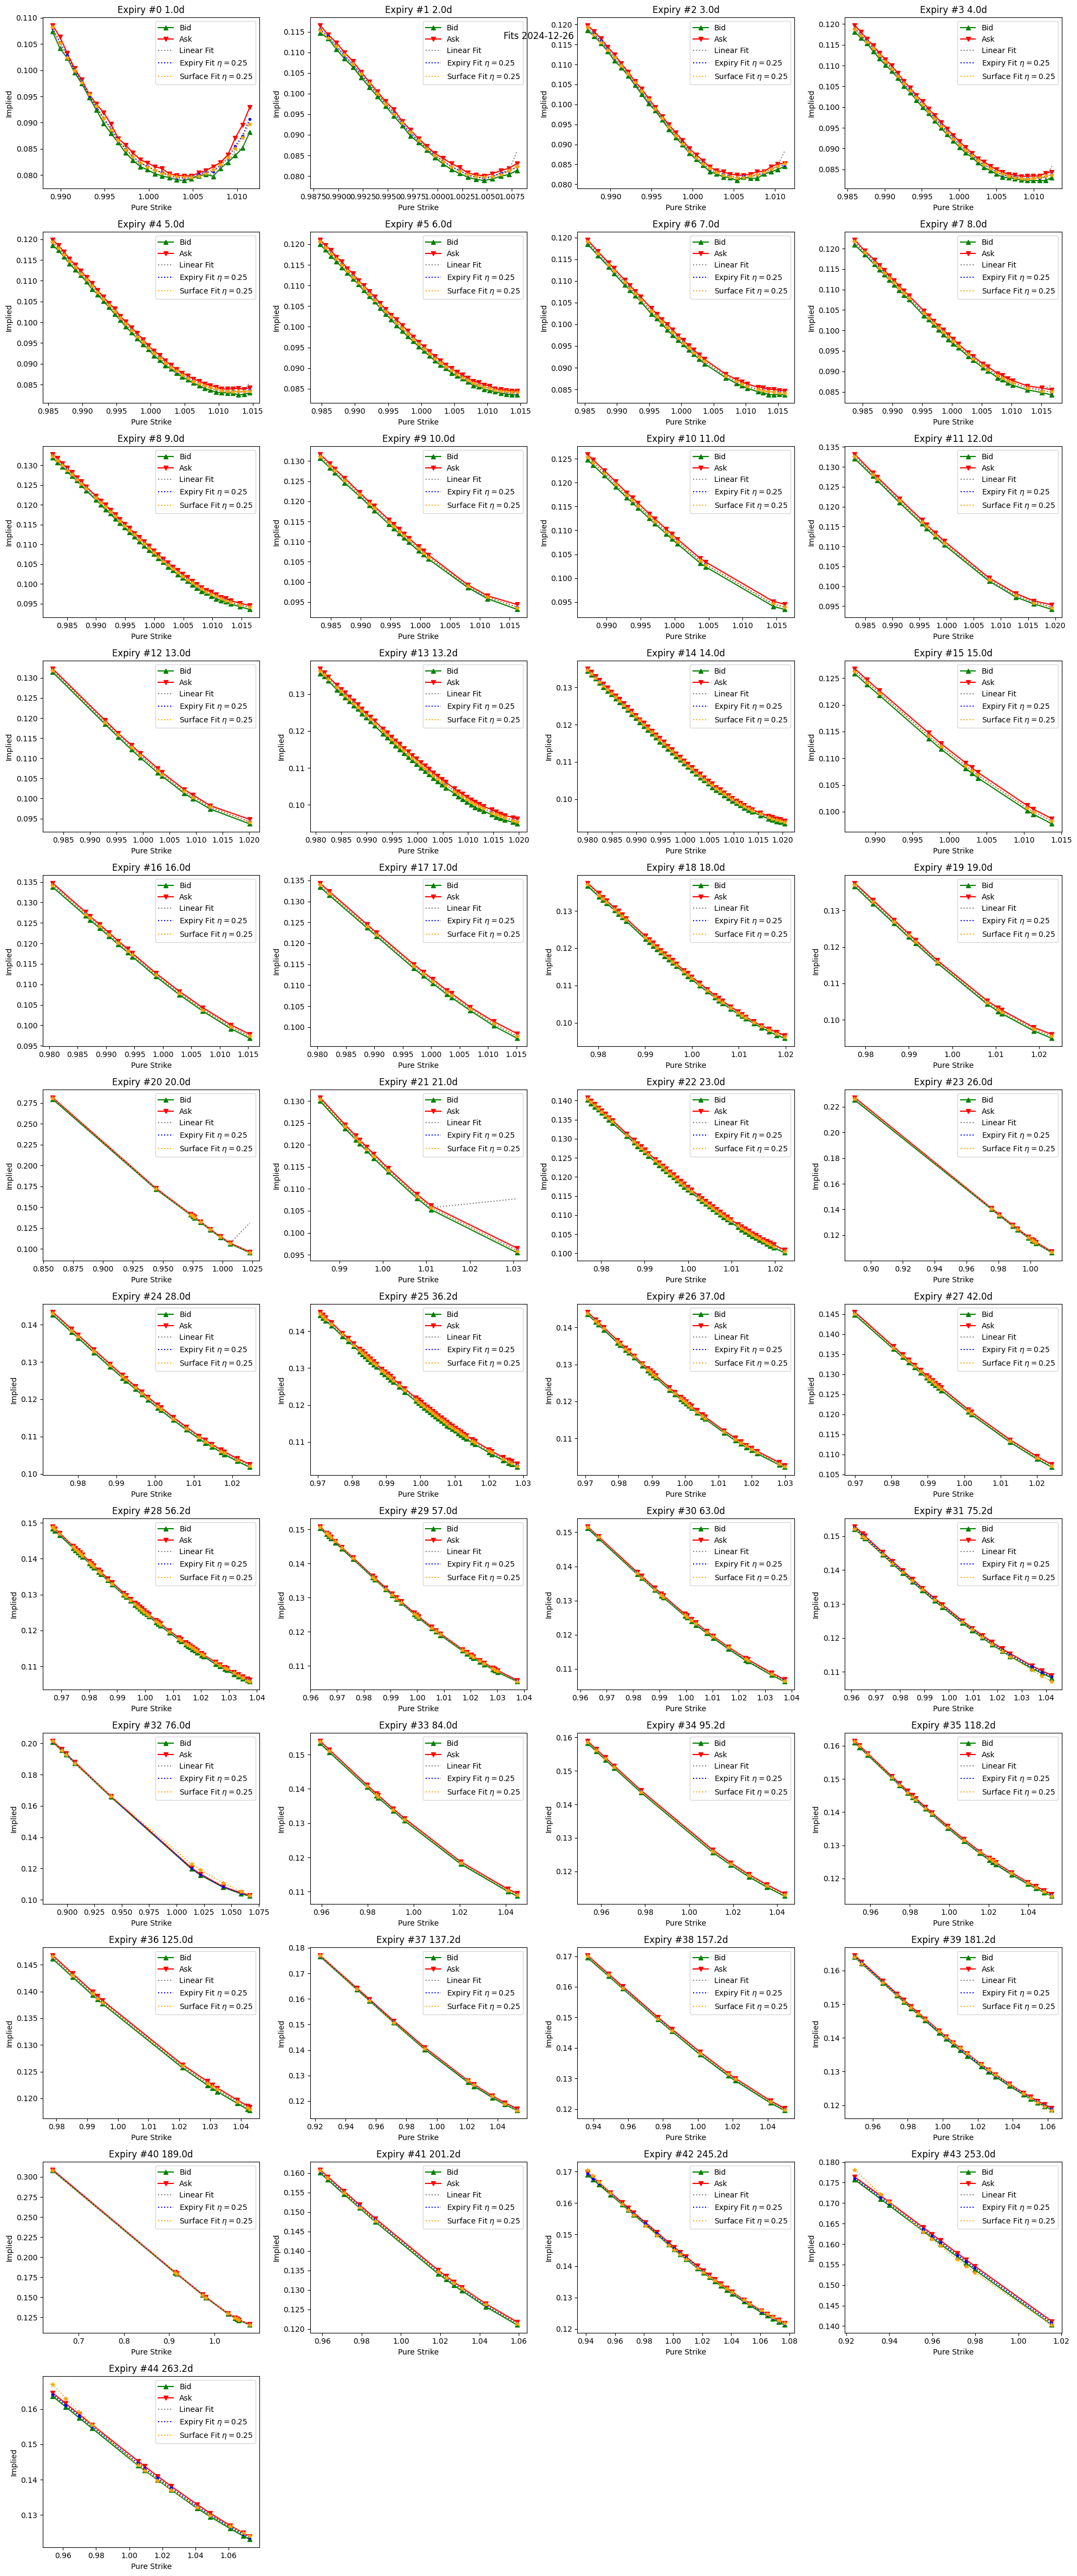

00: Surface 2024-12-26 expiry #0 1.0d: Generating extended strikes... using 30 extended strikes based on 28 market strikes.
00: Surface 2024-12-26 expiry #0 1.0d: Soft linear per-expiry no-arbitrage fit succeeded within bid/ask. This took 6.82ms.
00: Surface 2024-12-26 expiry #1 2.0d: Generating extended strikes... using 27 extended strikes based on 25 market strikes.
00: Surface 2024-12-26 expiry #1 2.0d: Soft linear per-expiry no-arbitrage fit succeeded within bid/ask. This took 6.09ms.
00: Surface 2024-12-26 expiry #2 3.0d: Generating extended strikes... using 32 extended strikes based on 30 market strikes.
00: Surface 2024-12-26 expiry #2 3.0d: Soft linear per-expiry no-arbitrage fit succeeded within bid/ask. This took 5.67ms.
00: Surface 2024-12-26 expiry #0 1.0d: Generating extended strikes... using 30 extended strikes based on 28 market strikes.
00: Surface 2024-12-26 expiry #0 1.0d: Soft linear per-expiry no-arbitrage fit succeeded within bid/ask. This took 6.82ms.
00: Surface 

In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.utils.arbfree

from cdxcore.bs import bs
from cdxcore.dynaplot import figure, store
from cdxcore.verbose import Context
from quantdata.biz_calendar import DAYS_PER_YEAR, to_date
from cdxcore.pretty import PrettyObject
import numpy as np

from quantdata.widb.options_filter import MkArbFree, RawDayFilter, ExpiryFilter, OptionsFilter, filter_options_day

def assess_fit(d, ticker = "SPX"):
    d = to_date(d)
    raw_day_filter = RawDayFilter()
    expiry_filter = ExpiryFilter()
    mk_arb_free = MkArbFree()
    options_filter = OptionsFilter()

    data = filter_options_day(ticker,d, mk_arb_free=mk_arb_free, options_filter=options_filter, raw_day_filter=raw_day_filter, expiry_filter=expiry_filter, verbose=Context.all )

    strikes = data['pure_strike'].to_numpy()
    tte_y   = data['tte_y'].to_numpy()
    bid_vol = data['bid_vol'].to_numpy()
    ask_vol = data['ask_vol'].to_numpy()
    fit_vol = data['fit1_vol'].to_numpy()
    bid     = data['pure_bid_price'].to_numpy()
    ask     = data['pure_ask_price'].to_numpy()

    ixs     = np.argsort(strikes)
    strikes = strikes[ixs]
    tte_y   = tte_y[ixs]
    bid_vol = bid_vol[ixs]
    ask_vol = ask_vol[ixs]
    fit_vol = fit_vol[ixs]
    bid     = bid[ixs]
    ask     = ask[ixs]
    del ixs

    # split into per-expiry
    # ---------------------

    afd = PrettyObject()

    afd.expiries = []
    afd.strikes  = []
    afd.bids     = []
    afd.asks     = []
    afd.fit_vols = []
    afd.ask_vols = []
    afd.bid_vols = []
    afd.mask     = []
    uttys        = np.unique(tte_y)

    for utty in uttys:
        mask = tte_y == utty
        afk = strikes[mask]
        assert np.all( np.diff(afk) > 0. ), f"Expected strikes to be strictly increasing for TTE {utty}, but found strikes {afk}"
        afd.mask.append(mask)
        afd.expiries.append( utty)
        afd.strikes.append( strikes[mask] )
        afd.bids.append( bid[mask] )
        afd.asks.append( ask[mask] )
        afd.fit_vols.append( fit_vol[mask] )
        afd.ask_vols.append( ask_vol[mask] )
        afd.bid_vols.append( bid_vol[mask] )
    afd.expiries = np.array(afd.expiries)

    with figure(f"Fits {d}", col_size=5, row_size=4, columns=4 ) as fig_fits:

        axs = []
        for t, expiry in enumerate(afd.expiries):
            ax = fig_fits.add_subplot(f"Expiry #{t} {expiry*DAYS_PER_YEAR:.1f}d")
            axs.append(ax)
            ax.set_xlabel("Pure Strike")
            ax.set_ylabel("Implied")

            strikes_t = afd.strikes[t]

            ax.plot(strikes_t, afd.bid_vols[t], "^-", color="green", label="Bid")
            ax.plot(strikes_t, afd.ask_vols[t], "v-", color="red", label="Ask")
            ax.plot(strikes_t, afd.fit_vols[t], ":", color="grey", label="Linear Fit")
            ax.legend()
        fig_fits.render()

        # Fit
        # ---

        mk_arb_free = MkArbFree( "surface", smoothness=0.25, mid_fit_weight=0.1 )
        af = mk_arb_free(
                expiries       = afd.expiries, 
                strikes        = afd.strikes,
                bids           = afd.bids,
                asks           = afd.asks,
                message_context= lambda : f"Surface {d}",
                verbose        = Context.all )

        afd.mfit1_vols = []
        afd.mfitX_vols = []

        for t, expiry in enumerate(afd.expiries):
            strikes_t = afd.strikes[t]
            mfit1, mfit1_vols = af.price( expiry, strikes_t, and_vols=True, mode="expiry" )
            mfitX, mfitX_vols = af.price( expiry, strikes_t, and_vols=True, mode="surface" )
            afd.mfit1_vols.append(mfit1_vols)
            afd.mfitX_vols.append(mfitX_vols)

            ax = axs[t]
            ax.plot(strikes_t, mfit1_vols, ":", color="blue", label=rf"Expiry Fit $\eta={mk_arb_free.smoothness:.2f}$")
            ax.plot(strikes_t, mfitX_vols, ":", color="orange", label=rf"Surface Fit $\eta={mk_arb_free.smoothness:.2f}$")

            if t in af.input_index:
                mt     = af.input_index[t]
                mask_t = af.masks[mt]
                mask_t = mask_t if not mask_t is None else slice(None)

                ax.plot(strikes_t[mask_t], mfit1_vols[mask_t], ".", color="blue")
                ax.plot(strikes_t[mask_t], mfitX_vols[mask_t], "*", color="orange")

            ax.legend(loc="upper right")

        fig_fits.render()
        return af

    # plot the grid
    # -------------

    with figure(f"Grid Geometry {d}", col_size=5, row_size=4, columns=None ) as fig_strikes:
        axD, axA, axATM = fig_strikes.add_subplots("Inner", "All", "ATM Vol Term Structure")
        axD.set_xlabel("Strike")
        axA.set_xlabel("Strike")
        axATM.set_xlabel("TTE")
        axD.set_ylabel("TTE (log-scale)")
        axA.set_ylabel("TTE (log-scale)")
        axATM.set_ylabel("ATM Vol")
        axA.set_yscale("log")
        axD.set_yscale("log")

        axATM.plot( afd.expiries, af.interpolate_atm_vols( afd.expiries ), ".-", color="orange" )

        for t, expiry in enumerate(afd.expiries):
            axD.plot( grid.strikes[t], grid.strikes[t]*0.+expiry*DAYS_PER_YEAR, ".:" )
            axA.plot( grid.mstrikes[t], grid.mstrikes[t]*0.+expiry*DAYS_PER_YEAR, ".:" )

af = assess_fit("2025-07-01")
af = assess_fit("2024-12-26")



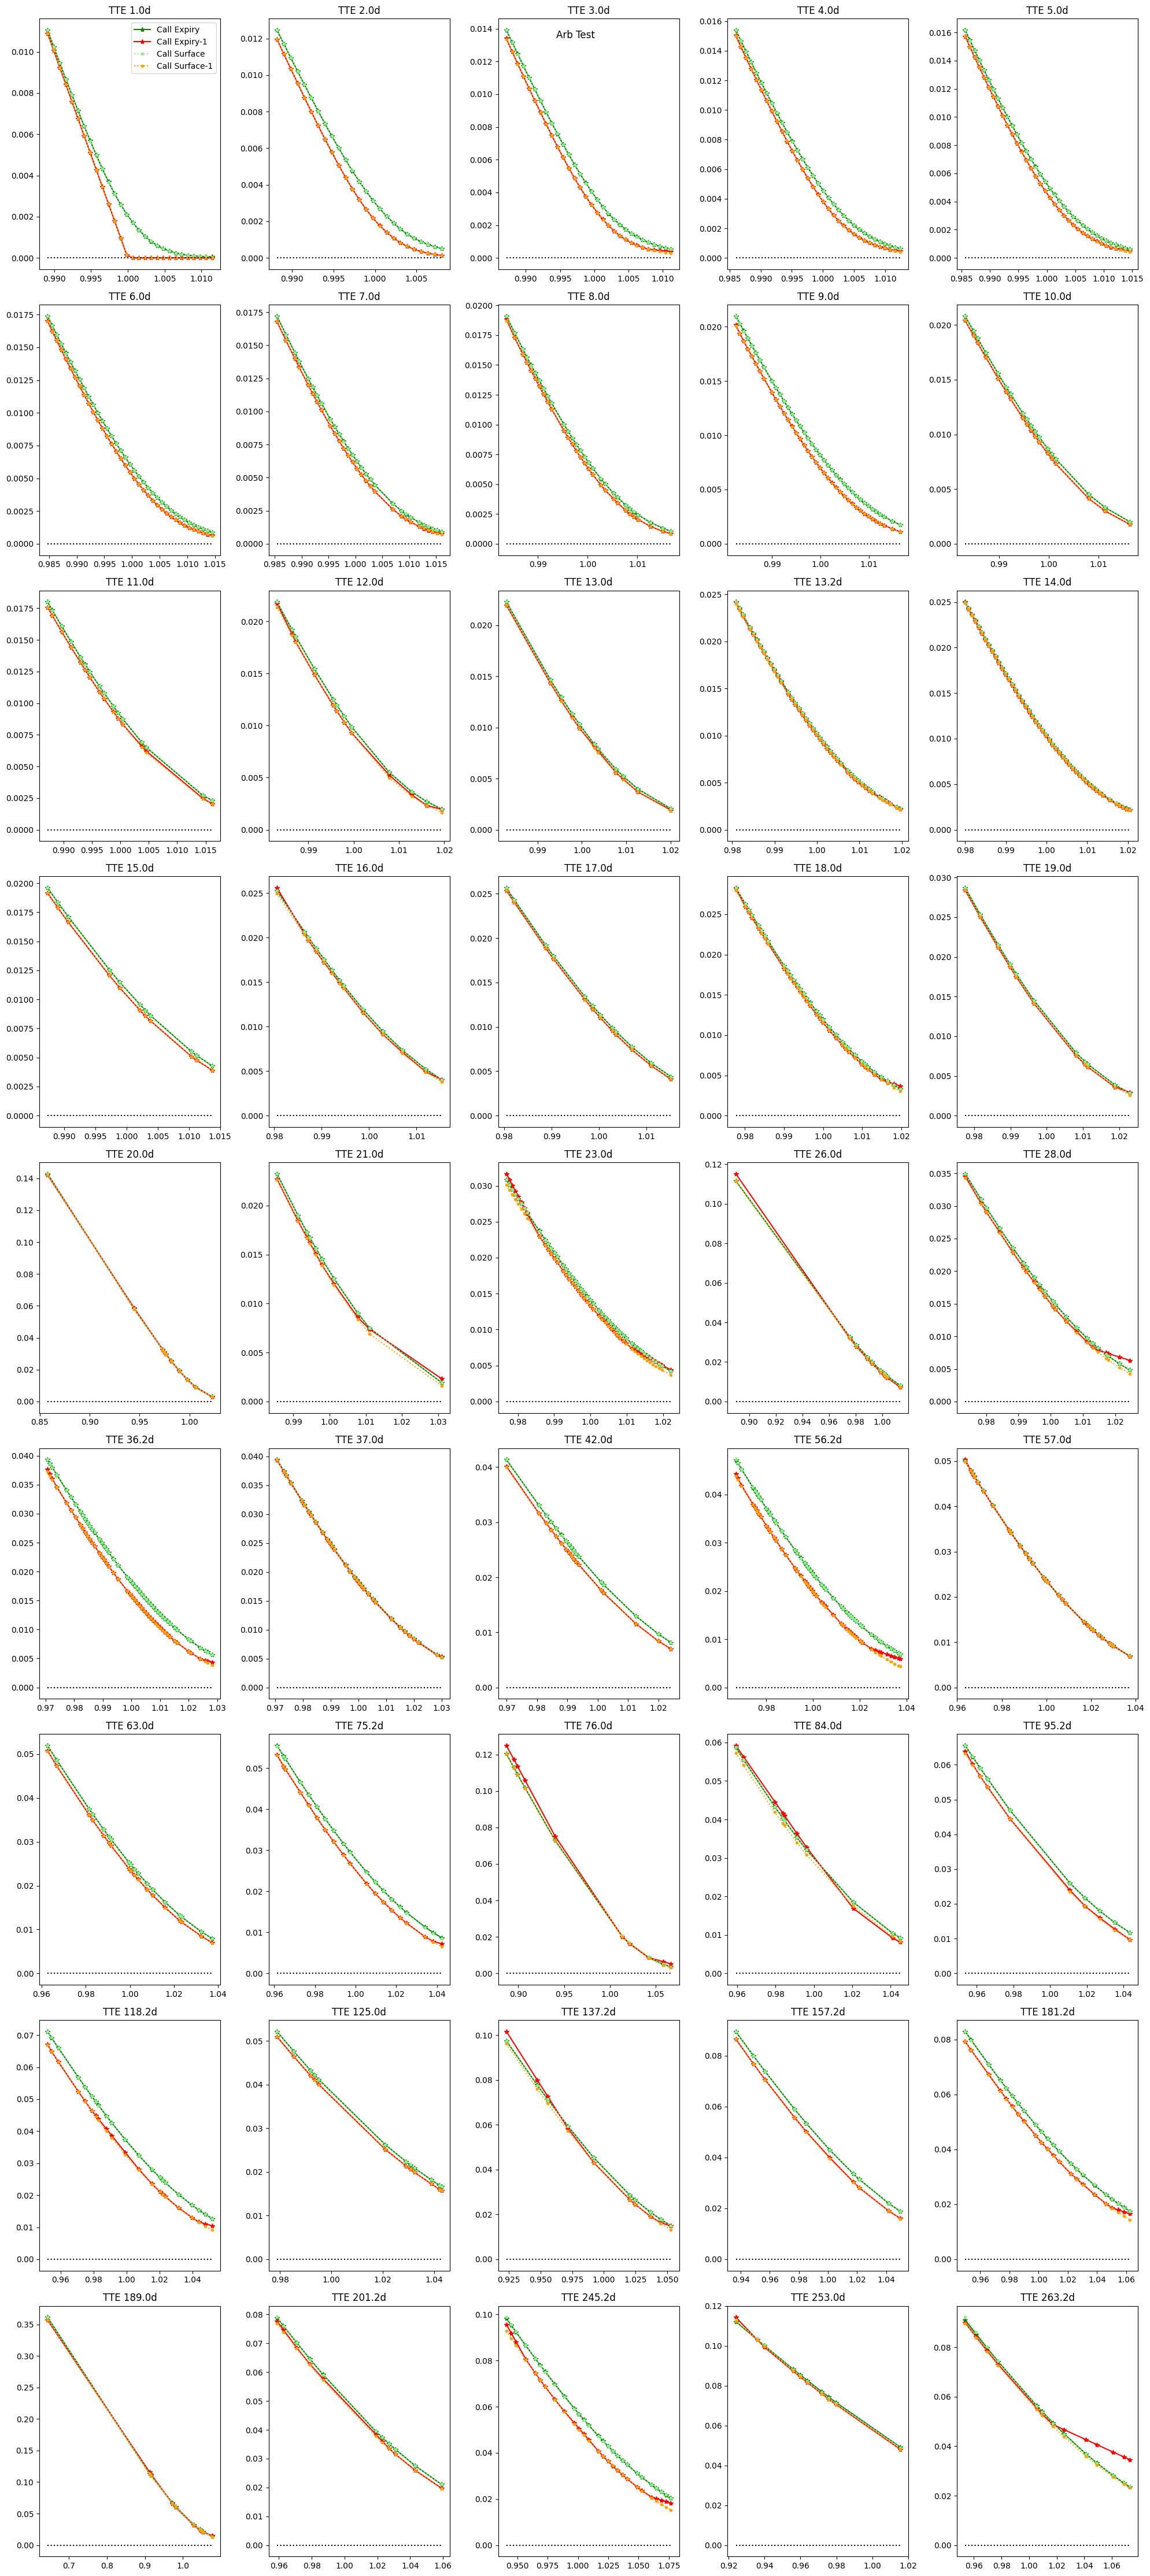

In [2]:
def arb_test(af):

    with figure("Arb Test") as fig:

        T = len(af.expiries)
        for t in range(T):
            expiry_tm1 = af.expiries[t-1] if t>0 else 0.
            expiry     = af.expiries[t]
            xstrikes_t = af.xstrikes[t]

            call_tm1   = af.price( expiry_tm1, xstrikes_t[1:-1], mode="expiry") 
            call_t     = af.price( expiry, xstrikes_t[1:-1], mode="expiry") 
            scall_tm1  = af.price( expiry_tm1, xstrikes_t[1:-1], mode="surface") 
            scall_t    = af.price( expiry, xstrikes_t[1:-1], mode="surface") 

            ax = fig.add_subplot(f"TTE {expiry*DAYS_PER_YEAR:.1f}d")
            ax.plot( xstrikes_t[1:-1], call_t, "*-", color="green", label="Call Expiry" )
            ax.plot( xstrikes_t[1:-1], call_tm1, "*-", color="red", label="Call Expiry-1" )
            ax.plot( xstrikes_t[1:-1], scall_t, ".:", color="lightgreen", label="Call Surface" )
            ax.plot( xstrikes_t[1:-1], scall_tm1, ".:", color="orange", label="Call Surface-1" )
            ax.plot( xstrikes_t[1:-1], xstrikes_t[1:-1]*0., ":", color="black")
            if t==0:
                ax.legend()

arb_test(af)






In [3]:
x = [1,2,3]
4 in x

False